## Example 6b: Antithetic Integral Controller — posterior concentration as $T$ grows

This notebook continues Example 6 (`example6_aic.ipynb`), the antithetic integral controller (AIC), which is ergodic under
the set-point condition $\mu/\theta > k/\gamma$. Because the process is ergodic (Condition 1 of the paper), the
consistency results apply, and the posterior should concentrate on the true rates as the observation time $T$ grows.

**Design.** We take the single long trajectory of Example 6 ($T = 5000$, `data/example6_trajectory.json`) and use its
**prefixes** up to $T \in \{100, 500, 1000, 5000\}$: the same realisation observed for longer and longer. For each $T$ we
run exactly the same Bayesian inference as in Example 6 (spike-and-slab prior, adaptive MCMC, same settings and seed).
The case $T = 5000$ is the full trajectory, so it reproduces Example 6.

**What to look for.**
* The credible intervals of the six active rates shrink roughly like $1/\sqrt{T}$ and contain the true values.
* The two active reactions that share the stoichiometric change $(+1,0,0)$, $\varnothing \to X$ and
  $Z_1 \to Z_1 + X$, are told apart better as $T$ grows.
* $\Pr(\text{off})$ of every inactive candidate reaction approaches 1.

**Outputs.**
* `data/example6_T{T}_trajectory.json`: the prefix trajectories (created from the full trajectory; deterministic).
* `results/example6_T{T}/`: MCMC summaries (`mcmc_summary.xlsx`) and plots for each $T$.
* `results/example6_Tsweep/`: summary table (`bayes_Tsweep.csv`) and figure (`posterior_vs_T.png`).
* `writing/fig_aic_posterior_vs_T.pdf`: the same figure for the manuscript.
* `writing/table_aic_bayes_Tsweep.tex`: LaTeX table of posterior means and credible intervals versus $T$.

**Check.** With `RUN_MCMC = True`, the run for $T = 5000$ reproduces `results/example6/mcmc_summary.xlsx` of Example 6
exactly (same trajectory, code path and seed; verified).

**Modes.** `RUN_MCMC = False` (default) only reads the saved MCMC summaries and rebuilds the tables and figure (seconds).
`RUN_MCMC = True` re-runs the MCMC for every $T$ in `T_LIST` (a few minutes in total).
The comparison with the LASSO method of Zhang et al. is in `example6_aic_lasso.ipynb`.


### Settings

In [1]:
import sys
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(".."))

from src.parsing import *
from src.inference import *
from src.mcmc import *

# False: read the saved MCMC summaries and rebuild tables/figure.  True: re-run the MCMC for every T.
RUN_MCMC = False

T_LIST = [100, 500, 1000, 5000]
FULL_TRAJECTORY = "../data/example6_trajectory.json"   # T = 5000, from example6_aic.ipynb
NETWORK_FILE    = "../data/example6_network.json"

# MCMC settings: identical to example6_aic.ipynb (and to every other example)
NIterates = 500_000
Burnin    = 50_000
Thinout   = 100
SEED      = 6          # same base seed as example6_aic.ipynb

def traj_file(T):
    return FULL_TRAJECTORY if T == 5000 else f"../data/example6_T{T}_trajectory.json"

def result_dir(T):
    return f"../results/example6_T{T}"

SWEEP_DIR = "../results/example6_Tsweep"
os.makedirs(SWEEP_DIR, exist_ok=True)
print("Mode:", "re-run MCMC" if RUN_MCMC else "post-processing only")


Mode: post-processing only


### Network

The network saved by Example 6 (true rates $k=2$, $\gamma=1$, $k_p=1$, $\mu=6$, $\theta=2$, $\eta=1$, and the full
library of 90 candidate reactions).

In [2]:
(reactionNetwork, CRN_stoichiometric_matrix, CRN_reaction_names, CRN_parameter_names,
 trueTheta, parameter_values, sampled_indices,
 reactant_matrix, unique_changes, compatible_reactions, species_names) = load_reaction_network(NETWORK_FILE)

# reaction names in the full library (same order as generate_reactions in Example 6)
complexes = np.array([
    [0, 1, 0, 0, 2, 0, 0, 1, 1, 0],   # X
    [0, 0, 1, 0, 0, 2, 0, 1, 0, 1],   # Z1
    [0, 0, 0, 1, 0, 0, 2, 0, 1, 1],   # Z2
])
_, _, _, reaction_names, _, _, _ = generate_reactions(complexes, species_names)
reaction_names = [r.rstrip(":") for r in reaction_names]

TRUE_REACTIONS = [i for i in range(len(trueTheta)) if trueTheta[i] > 0]
for i in TRUE_REACTIONS:
    print(f"{reaction_names[i]:16s} true rate {trueTheta[i]:g}")


Reaction network loaded from ../data/example6_network.json
  Species:   ['X', 'Z1', 'Z2']
  Reactions: 6 sampled  |  90 total in full CRN
  Unique stoichiometric changes: 54
Empty_to_X       true rate 2
Empty_to_Z1      true rate 6
X_to_Empty       true rate 1
X_to_X+Z2        true rate 2
Z1_to_X+Z1       true rate 1
Z1+Z2_to_Empty   true rate 1


### Prefix trajectories

The prefix up to $T$ keeps every recorded state with time $\le T$ and ends with a snapshot of the state at time $T$, the
same convention as the simulator's output (the parser treats the last row as a snapshot, not a jump).

In [3]:
full = json.load(open(FULL_TRAJECTORY))
t_full = np.array(full["time"])
assert t_full[-1] == 5000.0

def make_prefix(T):
    k = int(np.searchsorted(t_full, T, side="right"))       # rows with t <= T
    times, states = [float(x) for x in t_full[:k]], full["states"][:k]
    if times[-1] < T:
        times.append(float(T))
        states = states + [states[-1]]
    return times, states

for T in T_LIST:
    if T == 5000:
        continue
    times, states = make_prefix(T)
    path = traj_file(T)
    if os.path.exists(path):
        saved = json.load(open(path))
        assert saved["time"] == times and saved["states"] == states, f"{path} differs from the prefix of the full trajectory"
        print(f"T = {T:5d}: {path} matches the prefix ({len(times) - 2} events)")
    else:
        json.dump({"time": times, "states": states}, open(path, "w"))
        print(f"T = {T:5d}: wrote {path} ({len(times) - 2} events)")


T =   100: ../data/example6_T100_trajectory.json matches the prefix (2448 events)
T =   500: ../data/example6_T500_trajectory.json matches the prefix (12032 events)
T =  1000: ../data/example6_T1000_trajectory.json matches the prefix (24245 events)


### Bayesian inference for each $T$

Same code, settings and seeds as Example 6 (`run_channel_mcmc` in `src/mcmc.py`): MCMC is run for every stoichiometric
channel with at least one observed event, and each channel has its own seeded random streams, so $T = 5000$ reproduces
Example 6 exactly. Each channel's chain is saved (`..._chain.npz`), and `mcmc_summary.xlsx` includes the effective
sample size of the retained draws.

In [4]:
def run_mcmc_for_T(T):
    out_dir = result_dir(T)
    os.makedirs(out_dir, exist_ok=True)
    summary_file = os.path.join(out_dir, "mcmc_summary.xlsx")
    if os.path.exists(summary_file):
        os.remove(summary_file)            # summarize_chains appends, so start fresh

    time_list, state_list = load_trajectory(traj_file(T))
    unique_states, jump_counts, waiting_times, propensities = parse_trajectory(
        state_list, time_list, reactant_matrix, unique_changes, compatible_reactions, verbose=False)
    print(f"\n===== T = {T}: {len(time_list) - 2} events, {len(unique_states)} unique states")

    for index, deltaX in enumerate(unique_changes):
        (local_counts, local_waiting_times, local_propensities, selected_deltaX) = extract_local_data(
            jump_counts, waiting_times, propensities, unique_changes, index=index, deltaX=deltaX, verbose=False)
        total_count = sum(local_counts.values())
        if total_count == 0:
            continue
        localTheta = trueTheta[compatible_reactions[selected_deltaX]]
        print(f"  channel {tuple(int(x) for x in deltaX)}: {total_count} events, "
              f"candidates {[reaction_names[i] for i in compatible_reactions[selected_deltaX]]}")
        run_channel_mcmc(local_counts, local_waiting_times, local_propensities, localTheta, trueTheta,
                         results_dir=out_dir, index=index, total_count=total_count, seed=SEED,
                         NIterates=NIterates, Burnin=Burnin, Thinout=Thinout)

if RUN_MCMC:
    import io, contextlib
    for T in T_LIST:
        with contextlib.redirect_stdout(io.StringIO()) as buf:
            run_mcmc_for_T(T)
        print("\n".join(l for l in buf.getvalue().splitlines() if l.startswith(("=====", "  channel"))))
else:
    print("RUN_MCMC = False: reading saved summaries from", [result_dir(T) for T in T_LIST])


RUN_MCMC = False: reading saved summaries from ['../results/example6_T100', '../results/example6_T500', '../results/example6_T1000', '../results/example6_T5000']


### Results versus $T$

One row per candidate reaction in the observed channels. $\Pr(\text{off})$ is the posterior probability that the reaction
is absent. The 95% interval is reported for reactions with $\Pr(\text{off}) < 0.99$.

In [5]:
rows = []
for T in T_LIST:
    df = pd.read_excel(os.path.join(result_dir(T), "mcmc_summary.xlsx"))
    for _, r in df.iterrows():
        deltaX = unique_changes[int(r["Run_Index"])]
        rxn = compatible_reactions[deltaX][int(r["Param_Index"])]
        rows.append({"T": T, "channel": tuple(int(x) for x in deltaX), "reaction": reaction_names[rxn],
                     "reaction_index": rxn, "true": trueTheta[rxn], "events": int(r["Count"]),
                     "mean": r["Mean"], "lo": r["CI_lower"], "hi": r["CI_upper"], "Pr(off)": r["Prob_Off"]})
res = pd.DataFrame(rows)
res.to_csv(os.path.join(SWEEP_DIR, "bayes_Tsweep.csv"), index=False)

active = res[res["true"] > 0].copy()
active["width"] = active["hi"] - active["lo"]
active["covers"] = (active["lo"] <= active["true"]) & (active["true"] <= active["hi"])
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print("Active reactions:")
print(active.pivot_table(index="reaction", columns="T", values="mean").to_string())
print("\n95% interval width:")
print(active.pivot_table(index="reaction", columns="T", values="width").to_string())
print("\nTrue value inside the 95% interval:")
print(active.pivot_table(index="reaction", columns="T", values="covers", aggfunc="first").to_string())

inactive = res[res["true"] == 0]
print("\nInactive candidates: smallest Pr(off) at each T (1 = switched off with certainty)")
print(inactive.groupby("T")["Pr(off)"].min().to_string())
print("\nNumber of inactive candidates with Pr(off) < 0.95:")
print((inactive["Pr(off)"] < 0.95).groupby(inactive["T"]).sum().to_string())


Active reactions:
T                100    500    1000   5000
reaction                                  
Empty_to_X     2.0224 2.1153 2.0962 2.0366
Empty_to_Z1    6.0041 5.9562 5.9645 5.9914
X_to_Empty     0.9766 1.0336 1.0378 1.0005
X_to_X+Z2      1.8963 1.9962 1.9515 1.9986
Z1+Z2_to_Empty 0.9866 1.0281 1.0168 1.0069
Z1_to_X+Z1     0.9647 0.9363 0.9428 0.9579

95% interval width:


T                100    500    1000   5000
reaction                                  
Empty_to_X     0.7323 0.3270 0.2304 0.0996
Empty_to_Z1    0.9662 0.4294 0.3053 0.1347
X_to_Empty     0.2148 0.1038 0.0714 0.0322
X_to_X+Z2      0.3024 0.1433 0.0975 0.0464
Z1+Z2_to_Empty 0.1565 0.0727 0.0510 0.0225
Z1_to_X+Z1     0.5008 0.2503 0.1700 0.0836

True value inside the 95% interval:
T               100   500    1000   5000
reaction                                
Empty_to_X      True  True   True   True
Empty_to_Z1     True  True   True   True
X_to_Empty      True  True  False   True
X_to_X+Z2       True  True   True   True
Z1+Z2_to_Empty  True  True   True   True
Z1_to_X+Z1      True  True   True  False

Inactive candidates: smallest Pr(off) at each T (1 = switched off with certainty)
T
100    0.9944
500    0.9996
1000   1.0000
5000   0.9998

Number of inactive candidates with Pr(off) < 0.95:
T
100     0
500     0
1000    0
5000    0


### Figure: posterior concentration

Posterior mean and 95% credible interval of each active rate versus $T$ (log scale), divided by the true rate. The dashed
grey lines show $\pm 2/\sqrt{\text{events}}$ for the reaction's stoichiometric channel, the relative width expected
for a single rate estimated from that many events. For the two reactions that share the change $(+1,0,0)$
($\varnothing \to X$ and $Z_1 \to Z_1 + X$) the intervals are wider than this reference: the channel's events have to
be split between two reactions, which is possible only through the variation of $Z_1$ along the trajectory.

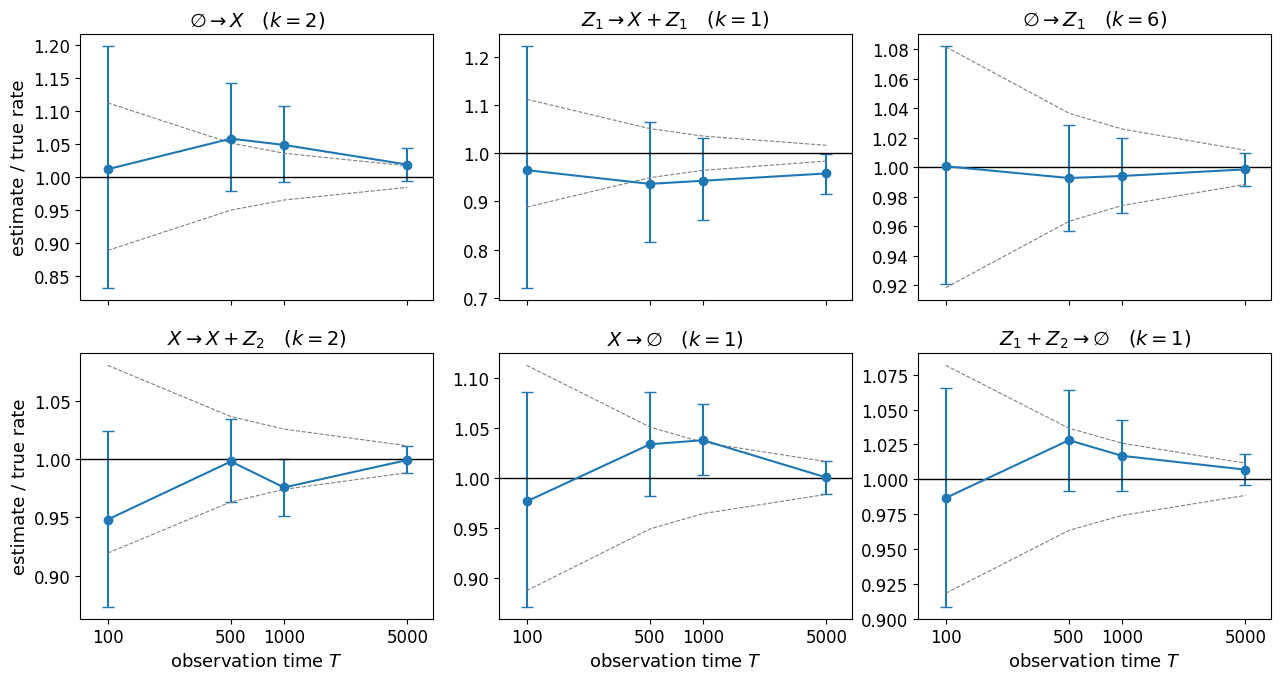

In [6]:
_rc_saved = {k: plt.rcParams[k] for k in ["font.size", "axes.titlesize", "axes.labelsize", "xtick.labelsize", "ytick.labelsize"]}
plt.rcParams.update({"font.size": 13, "axes.titlesize": 14, "axes.labelsize": 13,
                     "xtick.labelsize": 12, "ytick.labelsize": 12})
fig, axs = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for ax, (rxn, grp) in zip(axs.flat, active.groupby("reaction", sort=False)):
    g = grp.sort_values("T")
    k = g["true"].iloc[0]
    ax.errorbar(g["T"], g["mean"] / k, yerr=[(g["mean"] - g["lo"]) / k, (g["hi"] - g["mean"]) / k],
                fmt="o-", capsize=4, color="#1f77b4")
    ax.axhline(1.0, color="k", linewidth=1)
    ref = 2 / np.sqrt(g["events"].values)
    ax.plot(g["T"], 1 + ref, "--", color="grey", linewidth=0.8)
    ax.plot(g["T"], 1 - ref, "--", color="grey", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_xlim(70, 7000)
    ax.set_xticks(T_LIST)
    ax.set_xticklabels([str(T) for T in T_LIST])
    ax.minorticks_off()
    lhs, rhs = rxn.split("_to_")
    conv = lambda t: r"\emptyset" if t == "Empty" else t.replace("Z1", "Z_1").replace("Z2", "Z_2")
    ax.set_title(f"${conv(lhs)} \\to {conv(rhs)}$   ($k = {k:g}$)")
for ax in axs[:, 0]:
    ax.set_ylabel("estimate / true rate")
for ax in axs[1]:
    ax.set_xlabel("observation time $T$")
plt.tight_layout()
plt.savefig(os.path.join(SWEEP_DIR, "posterior_vs_T.png"), dpi=150)
plt.savefig("../writing/fig_aic_posterior_vs_T.pdf", bbox_inches="tight")     # figure for the manuscript
plt.rcParams.update(_rc_saved)
plt.show()


### LaTeX table

Written to `writing/table_aic_bayes_Tsweep.tex`: posterior mean (95% credible interval) of each active rate at each $T$,
and, per $T$, the smallest $\Pr(\text{off})$ among the inactive candidate reactions of the observed channels.

In [7]:
def tex_rxn(name):
    lhs, rhs = name.split("_to_")
    conv = lambda s: r"\varnothing" if s == "Empty" else s.replace("Z1", "Z_1").replace("Z2", "Z_2")
    return f"${conv(lhs)} \\to {conv(rhs)}$"

order = [reaction_names[i] for i in TRUE_REACTIONS]
L = [r"% Antithetic integral controller: posterior versus observation time T",
     r"% Generated by examples/example6_aic_Tsweep.ipynb -- do not edit by hand",
     r"\begin{table}[htbp]", r"\centering", r"\footnotesize", r"\setlength{\tabcolsep}{3pt}",
     r"\caption{Antithetic integral controller: posterior mean $\hat k$ and 95\% credible interval (CrI), "
     r"written $\hat k$ [CrI], of each active rate, "
     r"estimated from the prefix of a single trajectory up to time $T$. "
     r"Last row: smallest $\Pr(\text{off})$ among the inactive candidate reactions of the observed channels.}",
     r"\label{tab:aic_bayes_Tsweep}",
     r"\begin{tabular}{l r " + "l " * len(T_LIST) + "}", r"\toprule",
     r"Reaction & $k^*$ & " + " & ".join(f"$T={T}$" for T in T_LIST) + r" \\", r"\midrule"]
for name in order:
    g = active[active["reaction"] == name].set_index("T")
    cells = [f"{g.loc[T, 'mean']:.3f} [{g.loc[T, 'lo']:.3f}, {g.loc[T, 'hi']:.3f}]" for T in T_LIST]
    L.append(f"{tex_rxn(name)} & {g['true'].iloc[0]:g} & " + " & ".join(cells) + r" \\")
L.append(r"\midrule")
mins = inactive.groupby("T")["Pr(off)"].min()
L.append(r"\multicolumn{2}{l}{inactive: min $\Pr(\text{off})$} & " + " & ".join(f"{mins[T]:.3f}" for T in T_LIST) + r" \\")
L += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
out = "../writing/table_aic_bayes_Tsweep.tex"
open(out, "w").write("\n".join(L) + "\n")
print("Saved:", out, "\n")
print("\n".join(L))


Saved: ../writing/table_aic_bayes_Tsweep.tex 

% Antithetic integral controller: posterior versus observation time T
% Generated by examples/example6_aic_Tsweep.ipynb -- do not edit by hand
\begin{table}[htbp]
\centering
\footnotesize
\setlength{\tabcolsep}{3pt}
\caption{Antithetic integral controller: posterior mean $\hat k$ and 95\% credible interval (CrI), written $\hat k$ [CrI], of each active rate, estimated from the prefix of a single trajectory up to time $T$. Last row: smallest $\Pr(\text{off})$ among the inactive candidate reactions of the observed channels.}
\label{tab:aic_bayes_Tsweep}
\begin{tabular}{l r l l l l }
\toprule
Reaction & $k^*$ & $T=100$ & $T=500$ & $T=1000$ & $T=5000$ \\
\midrule
$\varnothing \to X$ & 2 & 2.022 [1.663, 2.395] & 2.115 [1.956, 2.283] & 2.096 [1.983, 2.214] & 2.037 [1.988, 2.087] \\
$\varnothing \to Z_1$ & 6 & 6.004 [5.525, 6.491] & 5.956 [5.742, 6.172] & 5.965 [5.812, 6.117] & 5.991 [5.925, 6.059] \\
$X \to \varnothing$ & 1 & 0.977 [0.872, 1.086]